# AIML Classification Assignment
## Weather Type Classification using SVM, Decision Tree, KNN and Naive Bayes

**Dataset:** `weather_cleaned_preprocessed.csv`  
**Target:** `Weather_Type_Encoded`

Run the cells from top to bottom. When prompted in Google Colab, upload the weather CSV file. The notebook uses the already-preprocessed dataset and evaluates four classification algorithms.

In [1]:
# ============================================================
# AIML CLASSIFICATION ASSIGNMENT
# Weather Type Classification using SVM, Decision Tree, KNN
# and Naive Bayes
# Dataset: weather_cleaned_preprocessed.csv
# ============================================================

# If running in Google Colab, upload the CSV when prompted.
# If the file is already in the Colab working directory, this
# script will read it directly.

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42
TARGET = "Weather_Type_Encoded"
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. LOAD DATASET

In [2]:
# 1. LOAD DATASET
# ------------------------------------------------------------

DATA_PATH = "weather_cleaned_preprocessed.csv"

# Google Colab upload fallback
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("Please upload the weather CSV file.")
        DATA_PATH = csv_files[0]
    except ImportError:
        raise FileNotFoundError(
            "Place weather_cleaned_preprocessed.csv in the same folder "
            "as this Python script, or update DATA_PATH."
        )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (14741, 26)


,Latitude,Longitude,Altitude (m),Temperature,Dewpoint,Humidity,Wind Speed,Wind Direction,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km),Cloud Cover_cloudy,Cloud Cover_overcast,Cloud Cover_partly cloudy,Season_Spring,Season_Summer,Season_Winter,Location_inland,Location_mountain,Region_Arid / Desert,Region_Equatorial Tropical,Region_Mediterranean Maritime,Region_Nordic / Sub-Polar,Region_Temperate Continental,Weather_Type_Encoded
0,30.001,30.986,139.7,29.1,18.6,53,4.8,177.2,0.8,1001.8,10.0,16.1,False,False,False,False,True,False,True,False,True,False,False,False,False,3.0
1,40.611,-73.616,12.7,14.5,11.0,80,13.0,255.8,18.5,1011.7,4.0,6.2,False,False,True,True,False,False,False,False,False,False,False,False,True,0.0
2,35.917,139.934,7.6,11.0,4.5,64,9.7,184.6,18.9,1013.8,4.0,12.7,True,False,False,False,False,False,False,False,False,False,False,False,True,0.0
3,40.897,-73.663,13.3,17.4,-0.7,29,14.3,119.8,0.3,1016.4,11.0,20.0,False,False,False,True,False,False,False,False,False,False,False,False,True,3.0
4,28.195,76.832,198.2,22.7,10.5,46,10.4,137.1,0.5,995.6,8.0,14.0,False,False,True,False,False,False,True,False,True,False,False,False,False,3.0


## 2. UNDERSTANDING THE DATASET

In [3]:
# 2. UNDERSTANDING THE DATASET
# ------------------------------------------------------------

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' was not found.")

print("\nTarget class counts:")
display(df[TARGET].value_counts().sort_index().to_frame("Records"))

print("\nTarget class percentages:")
display(
    (df[TARGET].value_counts(normalize=True).sort_index() * 100)
    .round(2).to_frame("Percentage")
)

Column names:
['Latitude', 'Longitude', 'Altitude (m)', 'Temperature', 'Dewpoint', 'Humidity', 'Wind Speed', 'Wind Direction', 'Precipitation (%)', 'Atmospheric Pressure', 'UV Index', 'Visibility (km)', 'Cloud Cover_cloudy', 'Cloud Cover_overcast', 'Cloud Cover_partly cloudy', 'Season_Spring', 'Season_Summer', 'Season_Winter', 'Location_inland', 'Location_mountain', 'Region_Arid / Desert', 'Region_Equatorial Tropical', 'Region_Mediterranean Maritime', 'Region_Nordic / Sub-Polar', 'Region_Temperate Continental', 'Weather_Type_Encoded']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14741 entries, 0 to 14740
Data columns (total 26 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Latitude                       14741 non-null  float64
 1   Longitude                      14741 non-null  float64
 2   Altitude (m)                   14741 non-null  float64
 3   Temperature            

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Latitude,14741.0,NaN,NaN,NaN,40.752835,17.088247,3.1475,29.969,40.264,47.928,71.805
Longitude,14741.0,NaN,NaN,NaN,12.893884,64.751786,-105.797,-9.024,8.24,55.626,151.871
Altitude (m),14741.0,NaN,NaN,NaN,210.90927,294.586403,0.0,9.5,29.8,329.5,816.45
Temperature,14741.0,NaN,NaN,NaN,7.803071,16.825767,-28.4125,0.5,10.9,20.2,49.0
Dewpoint,14741.0,NaN,NaN,NaN,1.620575,14.659537,-32.1,-6.1,3.5,11.3,37.5
Humidity,14741.0,NaN,NaN,NaN,70.813513,23.262697,17.0,53.0,75.0,92.0,100.0
Wind Speed,14741.0,NaN,NaN,NaN,12.981524,6.05735,0.0,8.6,12.5,16.9,29.35
Wind Direction,14741.0,NaN,NaN,NaN,187.286575,73.058978,0.1,137.7,187.5,238.8,359.9
Precipitation (%),14741.0,NaN,NaN,NaN,44.183794,36.74995,0.0,5.5,34.7,79.9,100.0
Atmospheric Pressure,14741.0,NaN,NaN,NaN,985.967777,39.299283,904.1,969.6,1005.2,1012.1,1026.4



Missing values:


,Missing Values
Latitude,0
Longitude,0
Altitude (m),0
Temperature,0
Dewpoint,0
Humidity,0
Wind Speed,0
Wind Direction,0
Precipitation (%),0
Atmospheric Pressure,0



Duplicate rows: 0

Target class counts:


,Records
Weather_Type_Encoded,
0.0,3761
1.0,3596
2.0,3700
3.0,3683



Target class percentages:


,Percentage
Weather_Type_Encoded,
0.0,25.52
1.0,24.40
2.0,25.10
3.0,24.99


## 3. DATA VALIDATION AND FEATURE/TARGET SEPARATION

In [6]:
# 3. DATA VALIDATION AND FEATURE/TARGET SEPARATION
# ------------------------------------------------------------

# The uploaded CSV is already preprocessed:
# - categorical features have already been encoded
# - cloud cover, season, location and region are represented
#   by Boolean indicator columns
# - there are no missing values in the supplied file
#
# Do not apply OneHotEncoder again.

# Clean any unexpected duplicate or missing values
df = df.drop_duplicates().dropna(subset=[TARGET]).copy()

X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

# Map potential boolean/string representation to integers 1 and 0
def clean_bool_cols(val):
    if pd.isna(val):
        return 0
    if isinstance(val, bool):
        return 1 if val else 0
    val_str = str(val).strip().lower()
    if val_str in ['true', '1', '1.0', 'yes']:
        return 1
    if val_str in ['false', '0', '0.0', 'no']:
        return 0
    return val

# Clean and convert all object and boolean columns to numeric representation
for col in X.columns:
    if X[col].dtype == 'object' or X[col].dtype == 'bool':
        X[col] = X[col].map(clean_bool_cols)

# Ensure all feature columns are fully numeric.
X = X.apply(pd.to_numeric, errors="raise")

print("\nNumber of input features:", X.shape[1])
print("Number of records:", X.shape[0])
print("Target classes:", sorted(y.unique()))


Number of input features: 25
Number of records: 14740
Target classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


## 4. EXPLORATORY DATA ANALYSIS (EDA)

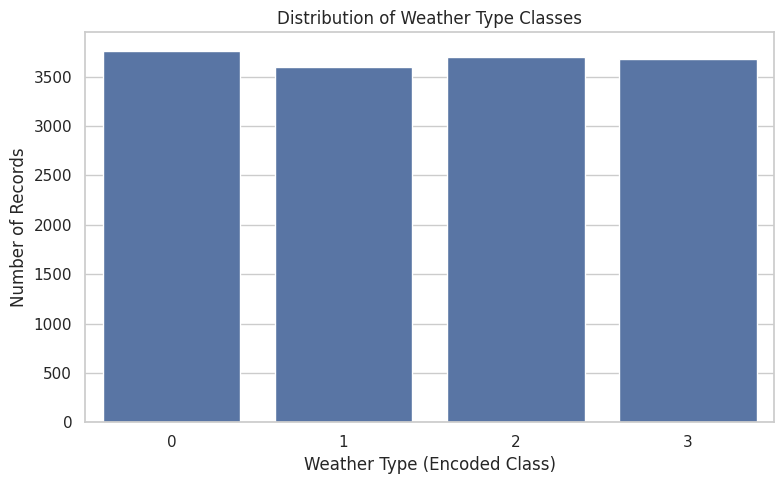

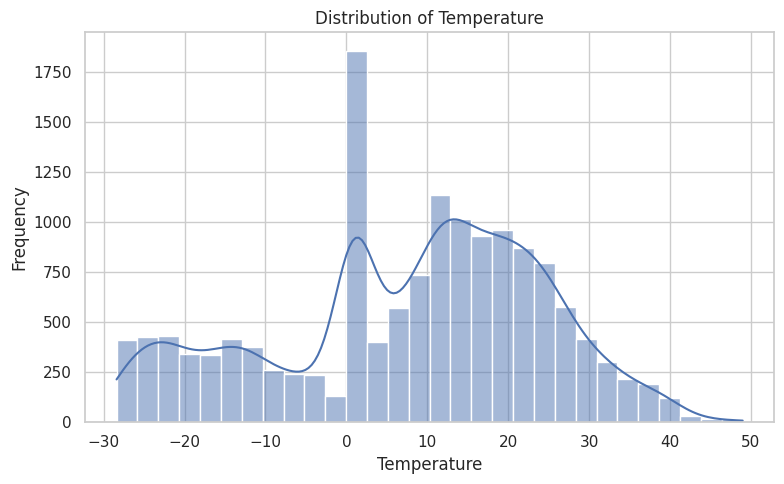

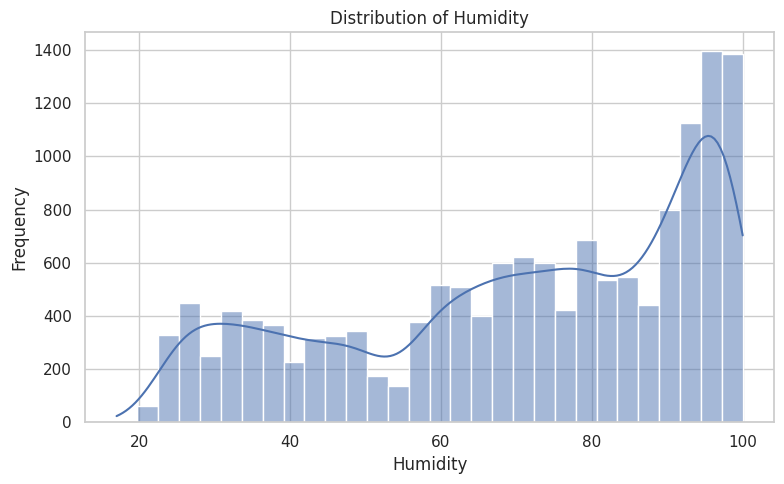

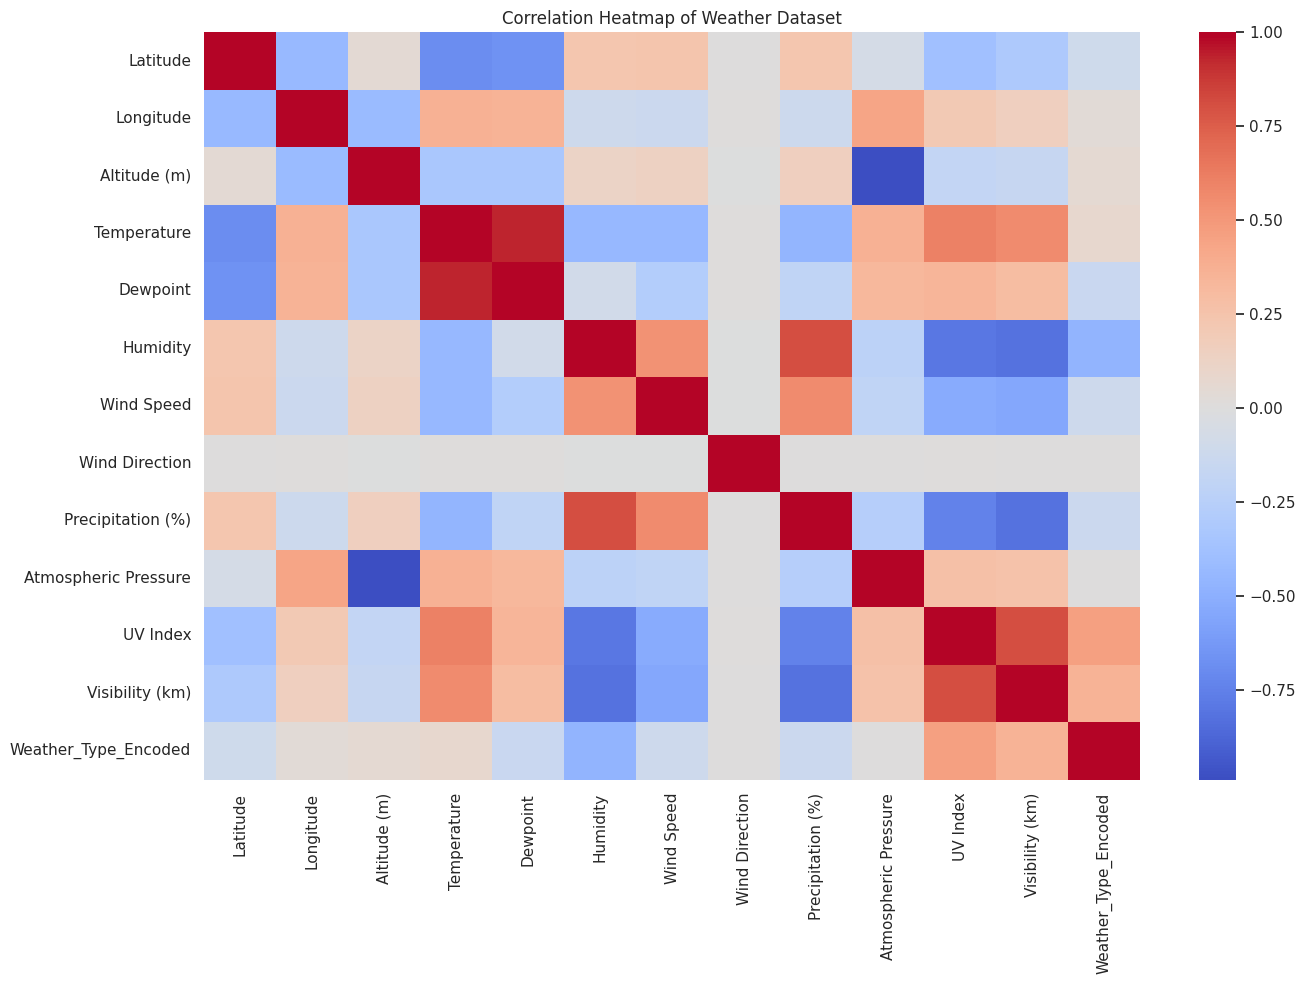

Average weather measurements for each encoded class:


,Temperature,Humidity,Wind Speed,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km)
Weather_Type_Encoded,,,,,,,
0.0,8.37,68.46,11.08,16.26,992.85,3.03,9.03
1.0,15.97,91.62,15.03,81.70,986.25,1.53,4.44
2.0,-15.86,86.77,17.87,77.58,964.34,0.40,3.22
3.0,23.02,36.87,8.01,2.51,1000.38,7.66,14.90


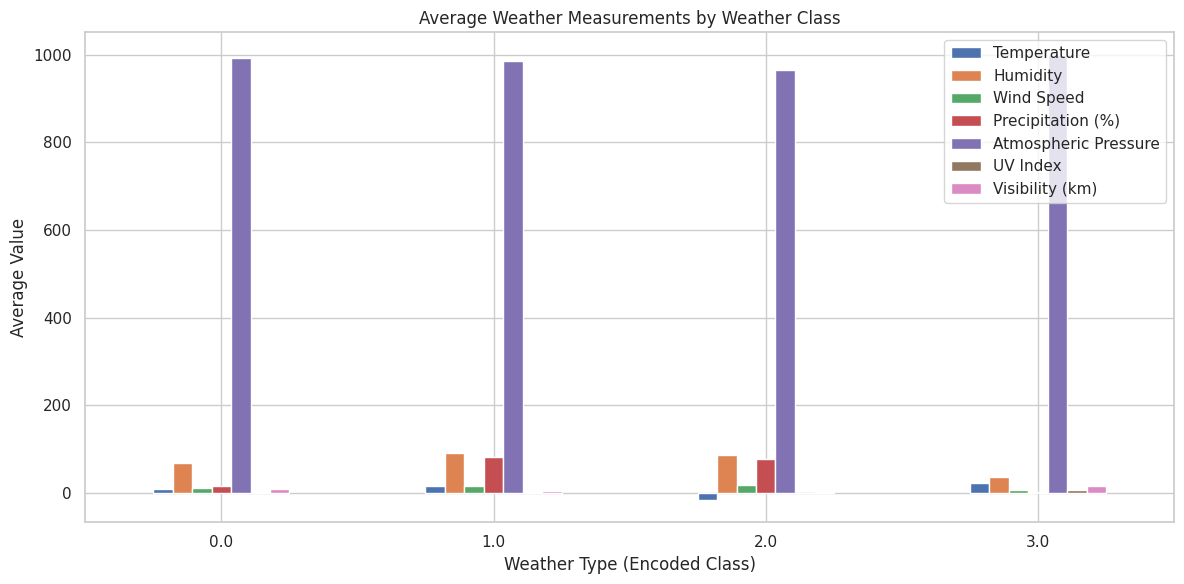

In [7]:
# 4. EXPLORATORY DATA ANALYSIS (EDA)
# ------------------------------------------------------------

# 4.1 Distribution of weather classes
plt.figure(figsize=(8, 5))
sns.countplot(x=y, order=sorted(y.unique()))
plt.title("Distribution of Weather Type Classes")
plt.xlabel("Weather Type (Encoded Class)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# 4.2 Temperature distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Temperature"], bins=30, kde=True)
plt.title("Distribution of Temperature")
plt.xlabel("Temperature")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 4.3 Humidity distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Humidity"], bins=30, kde=True)
plt.title("Distribution of Humidity")
plt.xlabel("Humidity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 4.4 Correlation heatmap for numeric variables
plt.figure(figsize=(14, 10))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap of Weather Dataset")
plt.tight_layout()
plt.show()

# 4.5 Average weather measurements by encoded class
weather_means = df.groupby(TARGET)[
    ["Temperature", "Humidity", "Wind Speed",
     "Precipitation (%)", "Atmospheric Pressure",
     "UV Index", "Visibility (km)"]
].mean()

print("Average weather measurements for each encoded class:")
display(weather_means.round(2))

weather_means.plot(kind="bar", figsize=(12, 6))
plt.title("Average Weather Measurements by Weather Class")
plt.xlabel("Weather Type (Encoded Class)")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. SPLIT DATASET INTO TRAINING AND TESTING SETS

In [8]:
# 5. SPLIT DATASET INTO TRAINING AND TESTING SETS
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining class distribution:")
display(y_train.value_counts().sort_index().to_frame("Training Records"))

print("\nTesting class distribution:")
display(y_test.value_counts().sort_index().to_frame("Testing Records"))

Training records: 11792
Testing records: 2948

Training class distribution:


,Training Records
Weather_Type_Encoded,
0,3009
1,2877
2,2960
3,2946



Testing class distribution:


,Testing Records
Weather_Type_Encoded,
0,752
1,719
2,740
3,737


## 6. MODEL IMPLEMENTATION

In [9]:
# 6. MODEL IMPLEMENTATION
# ------------------------------------------------------------

# Scaling is important for SVM, KNN and Gaussian Naive Bayes.
# Decision Tree does not require feature scaling.

# 6.1 Support Vector Machine (SVM)
svm_base = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(
        C=1.0,
        random_state=RANDOM_STATE,
        max_iter=10000
    ))
])

# Calibration provides class probabilities for log-loss evaluation.
# The estimator parameter is used in current scikit-learn versions.
svm_model = CalibratedClassifierCV(
    estimator=svm_base,
    method="sigmoid",
    cv=3
)

# 6.2 Decision Tree
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=15,
    min_samples_leaf=5,
    random_state=RANDOM_STATE
)

# 6.3 K-Nearest Neighbors (KNN)
knn_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski",
        p=2
    ))
])

# 6.4 Gaussian Naive Bayes
nb_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", GaussianNB())
])

models = {
    "SVM": svm_model,
    "Decision Tree": dt_model,
    "KNN": knn_model,
    "Naive Bayes": nb_model
}

# Train all four models
for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    model.fit(X_train, y_train)
    print(f"{model_name} training completed.")


Training SVM...
SVM training completed.

Training Decision Tree...
Decision Tree training completed.

Training KNN...
KNN training completed.

Training Naive Bayes...
Naive Bayes training completed.


## 7. MODEL EVALUATION

In [10]:
# 7. MODEL EVALUATION
# ------------------------------------------------------------

results = []

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Weighted)": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall (Weighted)": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-score (Weighted)": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Log Loss": log_loss(
            y_test, y_prob, labels=model.classes_
        )
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-score (Weighted)",
    ascending=False
).reset_index(drop=True)

print("\nModel comparison:")
display(results_df.round(4))


Model comparison:


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-score (Weighted),F1-score (Macro),Log Loss
0,Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
1,SVM,0.9986,0.9986,0.9986,0.9986,0.9986,0.0177
2,KNN,0.9817,0.9817,0.9817,0.9817,0.9816,0.1212
3,Naive Bayes,0.8134,0.8780,0.8134,0.8117,0.8108,2.4400


## 8. CLASSIFICATION REPORT FOR EACH MODEL

In [11]:
# 8. CLASSIFICATION REPORT FOR EACH MODEL
# ------------------------------------------------------------

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)
    print(classification_report(y_test, y_pred, zero_division=0))


SVM
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       752
           1       1.00      1.00      1.00       719
           2       1.00      1.00      1.00       740
           3       1.00      1.00      1.00       737

    accuracy                           1.00      2948
   macro avg       1.00      1.00      1.00      2948
weighted avg       1.00      1.00      1.00      2948


Decision Tree
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       752
           1       1.00      1.00      1.00       719
           2       1.00      1.00      1.00       740
           3       1.00      1.00      1.00       737

    accuracy                           1.00      2948
   macro avg       1.00      1.00      1.00      2948
weighted avg       1.00      1.00      1.00      2948


KNN
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       

## 9. CONFUSION MATRICES

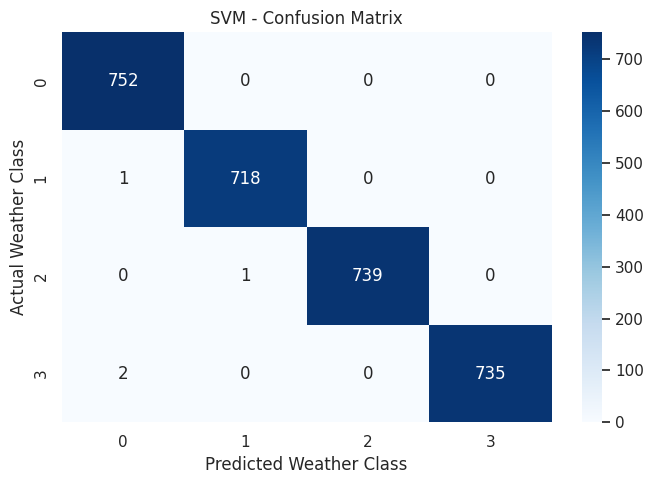

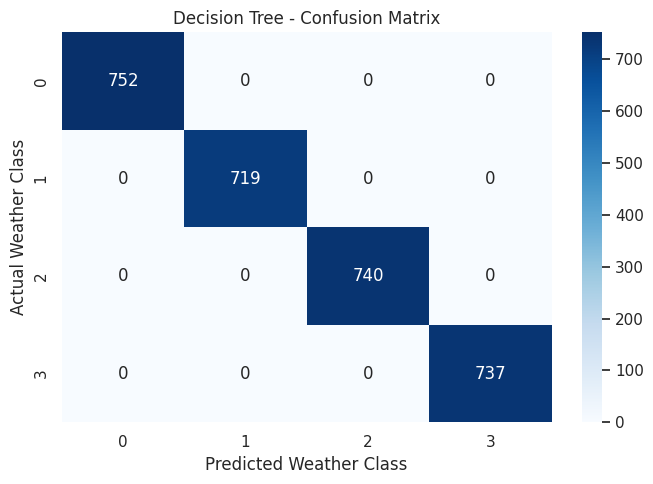

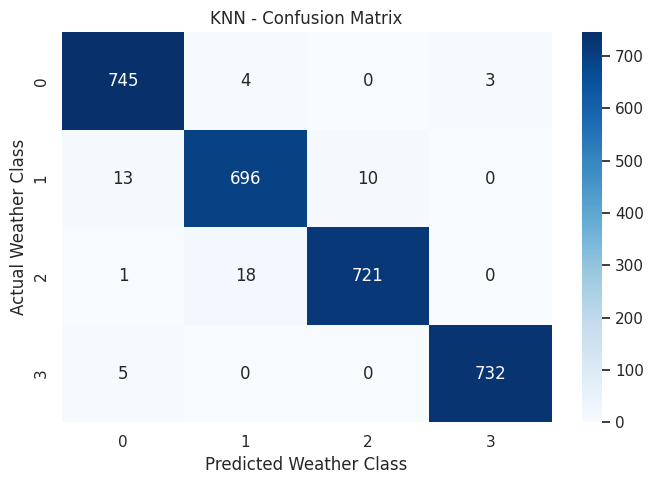

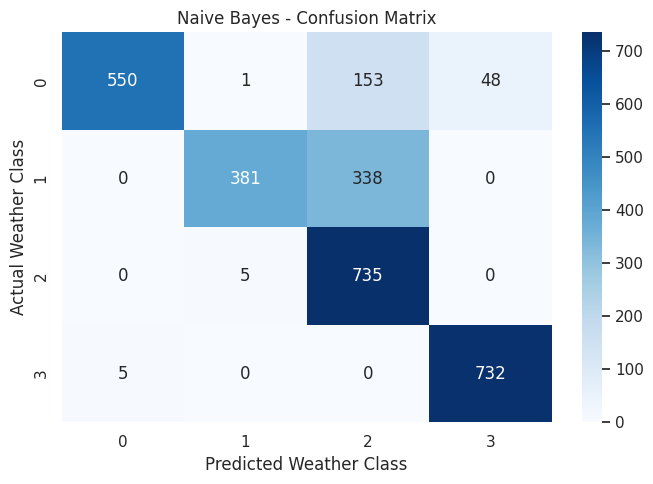

In [12]:
# 9. CONFUSION MATRICES
# ------------------------------------------------------------

class_labels = sorted(y.unique())

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels
    )
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Weather Class")
    plt.ylabel("Actual Weather Class")
    plt.tight_layout()
    plt.show()

## 10. COMPARATIVE ANALYSIS

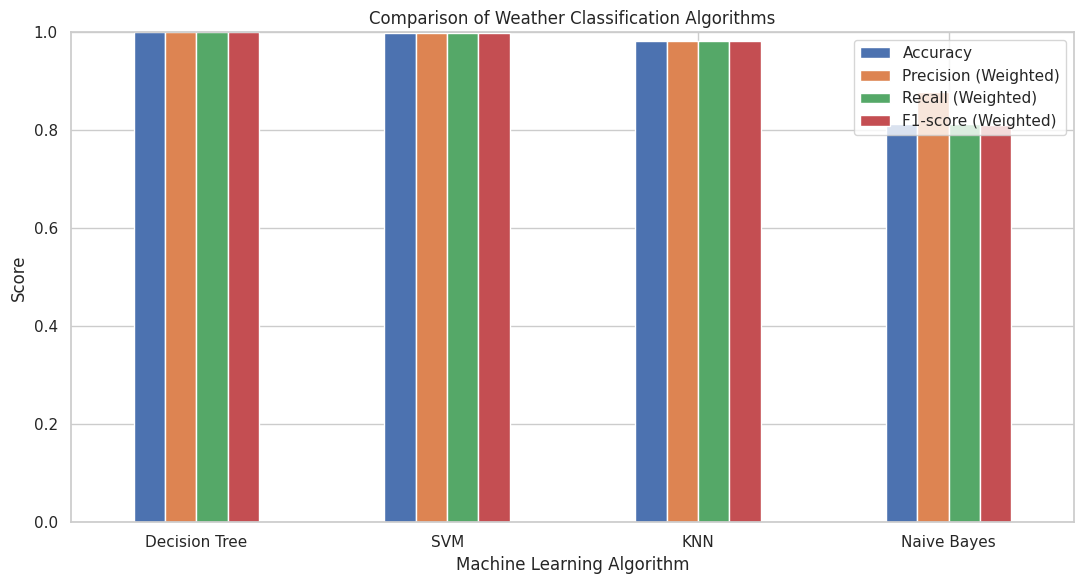

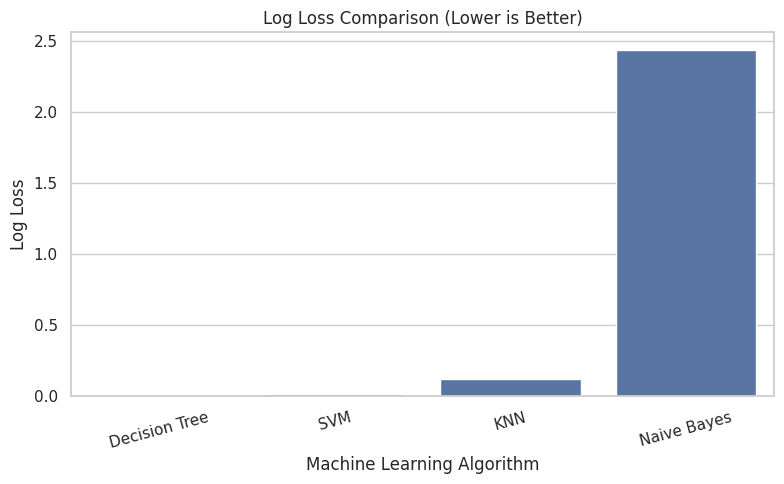

In [13]:
# 10. COMPARATIVE ANALYSIS
# ------------------------------------------------------------

plot_metrics = [
    "Accuracy",
    "Precision (Weighted)",
    "Recall (Weighted)",
    "F1-score (Weighted)"
]

results_plot = results_df.set_index("Model")[plot_metrics]
ax = results_plot.plot(kind="bar", figsize=(11, 6))
ax.set_title("Comparison of Weather Classification Algorithms")
ax.set_xlabel("Machine Learning Algorithm")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Model", y="Log Loss")
plt.title("Log Loss Comparison (Lower is Better)")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Log Loss")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 11. IDENTIFY THE BEST MODEL

In [14]:
# 11. IDENTIFY THE BEST MODEL
# ------------------------------------------------------------

best_f1_row = results_df.loc[
    results_df["F1-score (Weighted)"].idxmax()
]
best_accuracy_row = results_df.loc[
    results_df["Accuracy"].idxmax()
]
best_logloss_row = results_df.loc[
    results_df["Log Loss"].idxmin()
]

print(
    f"Best model based on weighted F1-score: "
    f"{best_f1_row['Model']} "
    f"({best_f1_row['F1-score (Weighted)']:.4f})"
)

print(
    f"Best model based on accuracy: "
    f"{best_accuracy_row['Model']} "
    f"({best_accuracy_row['Accuracy']:.4f})"
)

print(
    f"Best model based on lowest log loss: "
    f"{best_logloss_row['Model']} "
    f"({best_logloss_row['Log Loss']:.4f})"
)

Best model based on weighted F1-score: Decision Tree (1.0000)
Best model based on accuracy: Decision Tree (1.0000)
Best model based on lowest log loss: Decision Tree (0.0000)


## 12. PREDICT WEATHER TYPE FOR NEW RECORDS

In [15]:
# 12. PREDICT WEATHER TYPE FOR NEW RECORDS
# ------------------------------------------------------------

# Example: predict the class of an existing test record.
sample_record = X_test.iloc[[0]]
actual_class = y_test.iloc[0]

best_model = models[best_f1_row["Model"]]
predicted_class = best_model.predict(sample_record)[0]
predicted_probabilities = best_model.predict_proba(sample_record)[0]

print("\nExample prediction using the best weighted-F1 model:")
print("Actual encoded class:", actual_class)
print("Predicted encoded class:", predicted_class)
print("Class probabilities:")
for class_name, probability in zip(
    best_model.classes_, predicted_probabilities
):
    print(f"Class {class_name}: {probability:.4f}")


Example prediction using the best weighted-F1 model:
Actual encoded class: 0
Predicted encoded class: 0
Class probabilities:
Class 0: 1.0000
Class 1: 0.0000
Class 2: 0.0000
Class 3: 0.0000


## 13. SAVE RESULTS

In [16]:
# 13. SAVE RESULTS
# ------------------------------------------------------------

results_df.to_csv("weather_classification_model_comparison.csv", index=False)
print("\nEvaluation results saved to:")
print(os.path.abspath("weather_classification_model_comparison.csv"))

# Save the classification reports in a text file.
with open("weather_classification_reports.txt", "w") as f:
    for model_name, model in models.items():
        y_pred = model.predict(X_test)
        f.write("\n" + "=" * 60 + "\n")
        f.write(model_name + "\n")
        f.write("=" * 60 + "\n")
        f.write(classification_report(y_test, y_pred, zero_division=0))

print("Classification reports saved to weather_classification_reports.txt")


Evaluation results saved to:
/content/weather_classification_model_comparison.csv
Classification reports saved to weather_classification_reports.txt
